# ДЗ-1. Персональные top-10 рекомендации товаров
**Вейда Никита Альбертович**  
**Датасет:** UCI Online Retail · **seed:** 42 · **основная метрика:** NDCG@10.

Пять моделей реализованы самостоятельно в `models/`: ItemKNN, iALS, EASE, FM с метаданными и iALS с частотно-временным таргетом. Дополнительный эксперимент — FM без метаданных. Рекомендуем новые для пользователя товары; релевантность — факт положительной покупки в будущем окне.

Все таблицы и графики ниже получаются выполнением ячеек. Настройки выбираются по validation, затем фиксируются до единственного финального сравнения на test. Итоговые выводы находятся в разделе 7.
**Результат выполненного запуска:** EASE лидирует на test (NDCG@10 = 0,10285; Recall@10 = 0,06324). Собственный таргет ухудшил iALS, а прирост FM от метаданных статистически неубедителен. Test-когорта: 1 440 пользователей. Подробности и интервалы — в разделах 6–7.


## 1. Запуск и воспроизводимость
Из корня репозитория, Python 3.12:
```bash
python -m venv .venv
source .venv/bin/activate  # Windows: .venv\Scripts\activate
python -m pip install -r requirements.txt
python -m unittest discover -s tests -v
python run_notebook.py
```
Первый запуск автоматически скачивает архив UCI (~23 МБ) в `data/`, проверяет SHA-256 и читает Excel. Затем сохраняется локальный кеш чтения. Данные и окружение исключены из Git. Переменная `RECSYS_DATA_DIR` позволяет сменить каталог данных. Готовые результаты доступны в сохранённых выводах ноутбука; запуск заново повторяет обучение, а не подставляет таблицы из CSV. Вычисления выполняются на CPU с одним потоком BLAS/PyTorch для устойчивой воспроизводимости. Время зависит от компьютера.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import json, platform, random, time
from pathlib import Path
import importlib.metadata
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_pipeline import load_raw, clean_data, build_training, evaluation_cohort, VALID_START, TEST_START, DATA_URL, DATA_SHA256
from evaluation import paired_bootstrap
from experiment import SEARCH, SEED, PRIMARY_METRIC, search_models, final_evaluation

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
thread_limits = threadpool_limits(limits=1)
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 4.4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'figure.dpi': 120})
BLUE, GOLD, ORANGE = '#285A8E', '#B18B2D', '#C36638'
versions = {p: importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','matplotlib','openpyxl','nbformat','nbclient']}
environment = {'python': platform.python_version(), 'platform': platform.platform(),
               'versions': versions, 'seed': SEED, 'primary_metric': PRIMARY_METRIC,
               'blas_threads': 1, 'torch_threads': 1}
(RESULTS/'environment.json').write_text(json.dumps(environment, indent=2))
display(pd.Series(versions, name='Версия').to_frame())

,Версия
numpy,2.2.6
scipy,1.15.3
pandas,2.2.3
torch,2.6.0
matplotlib,3.10.1
openpyxl,3.1.5
nbformat,5.10.4
nbclient,0.10.2


## 2. Данные и EDA
[Первоисточник UCI](https://archive.ics.uci.edu/dataset/352/online+retail): Chen, D. (2015), *Online Retail*, [DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33), лицензия CC BY 4.0. Это покупки британского интернет-магазина с 01.12.2010 по 09.12.2011, включая оптовиков. Dataset не является MovieLens, Netflix Prize или Last.fm. Используется вся подходящая выборка, без случайной подвыборки.

| Поле | Смысл и использование |
|---|---|
| CustomerID | Идентификатор покупателя, пользователь рекомендательной системы |
| StockCode | Идентификатор товара, объект рекомендации |
| InvoiceNo | Номер чека; префикс C означает отмену |
| InvoiceDate | Время покупки, временное разбиение и давность |
| Quantity | Количество единиц; проверка положительного взаимодействия |
| UnitPrice | Цена в GBP; историческая медиана для ценового признака FM |
| Description | Название товара; слова как метапризнаки FM |
| Country | Страна покупателя; только описательная статистика |

**Единица взаимодействия:** одна покупка товара в одном чеке одним пользователем. Несколько единиц товара не считаются независимыми положительными примерами. Полные дубликаты удаляются, повторные покупки в разных чеках сохраняются. Отмены, неположительные количества/цены, неизвестные пользователи и служебные товарные коды исключаются. Обычные товары распознаются по пяти цифрам и не более двум буквам в коде. Возвраты не связываются задним числом с прошлой покупкой: это исключает использование будущей информации, но оставляет риск шумного положительного сигнала.

In [2]:
raw = load_raw()
print(f'Исходный размер: {raw.shape[0]:,} строк × {raw.shape[1]} полей')
display(pd.DataFrame({'пропуски': raw.isna().sum(), 'доля': raw.isna().mean()}).round(4))
print('Полные дубликаты:', int(raw.duplicated().sum()))
events, cleaning = clean_data(raw)
display(cleaning)

Исходный размер: 541,909 строк × 8 полей


,пропуски,доля
InvoiceNo,0,0.0000
StockCode,0,0.0000
Description,1454,0.0027
Quantity,0,0.0000
InvoiceDate,0,0.0000
UnitPrice,0,0.0000
CustomerID,135080,0.2493
Country,0,0.0000


Полные дубликаты: 5268


,Этап,Строки
0,Исходные строки,541909
1,Без полных дубликатов,536641
2,"Известны покупатель, товар и время",401604
3,Положительные покупки по ненулевой цене,392692
4,Только товарные коды,391150
5,События покупатель–товар–чек,386326


In [3]:
unique_pairs = events[['CustomerID','StockCode']].drop_duplicates()
nu, ni = events.CustomerID.nunique(), events.StockCode.nunique()
summary = pd.Series({'события после очистки': len(events), 'пользователи': nu, 'товары': ni,
                     'уникальные user-item пары': len(unique_pairs),
                     'разреженность бинарной матрицы': 1-len(unique_pairs)/(nu*ni),
                     'начало': str(events.InvoiceDate.min()), 'конец': str(events.InvoiceDate.max())})
display(summary.to_frame('Значение'))
assert 100_000 <= len(events) <= 2_000_000 and nu >= 1000 and ni >= 1000
cleaning.to_csv(RESULTS/'cleaning.csv', index=False)

,Значение
события после очистки,386326
пользователи,4334
товары,3659
уникальные user-item пары,266221
разреженность бинарной матрицы,0.983212
начало,2010-12-01 08:26:00
конец,2011-12-09 12:50:00


### Активность и популярность
Гистограммы показывают количество **различных** товаров у покупателя и покупателей у товара. Логарифмические оси помогают увидеть длинный хвост, не исключая активных оптовиков. Это описание набора, а не правило отбора по будущей активности.

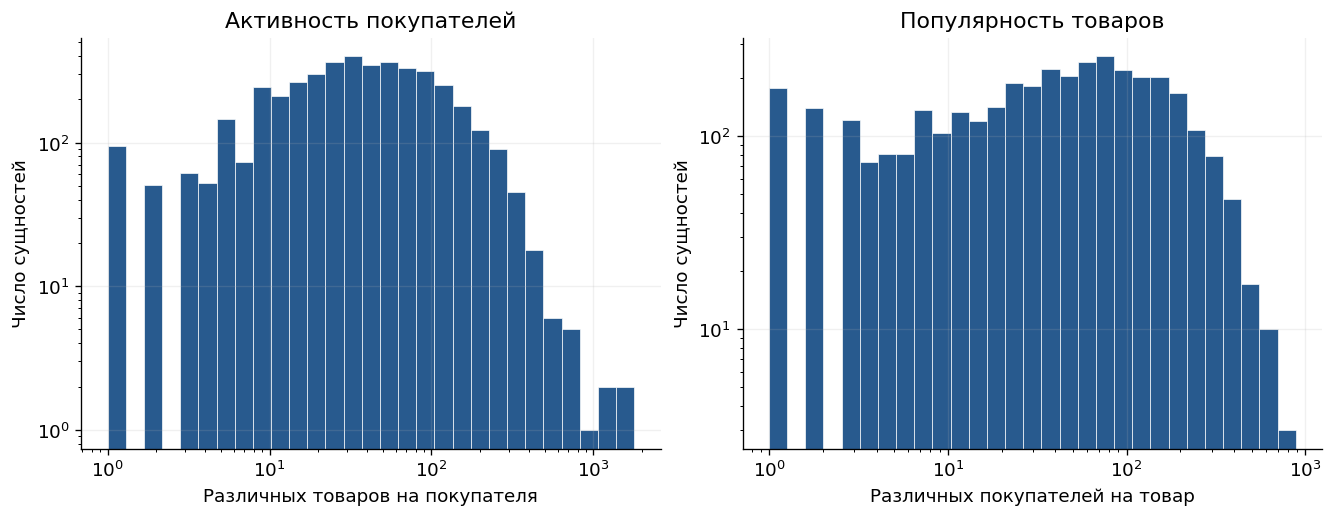

,Товаров у покупателя,Покупателей у товара
count,4334.0,3659.0
mean,61.4,72.8
std,85.3,91.6
min,1.0,1.0
25%,16.0,11.0
50%,35.0,40.0
75%,77.0,100.0
max,1785.0,881.0


In [4]:
activity = unique_pairs.groupby('CustomerID').size()
popularity = unique_pairs.groupby('StockCode').size()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
for ax, values, title, xlabel in [(axes[0], activity, 'Активность покупателей', 'Различных товаров на покупателя'),
                                  (axes[1], popularity, 'Популярность товаров', 'Различных покупателей на товар')]:
    bins = np.geomspace(1, values.max()+1, 30)
    ax.hist(values, bins=bins, color=BLUE, edgecolor='white', linewidth=.4)
    ax.set(xscale='log', yscale='log', title=title, xlabel=xlabel, ylabel='Число сущностей')
fig.savefig(RESULTS/'eda_distributions.png', bbox_inches='tight')
plt.show()
display(pd.DataFrame({'Товаров у покупателя': activity.describe(), 'Покупателей у товара': popularity.describe()}).round(1))

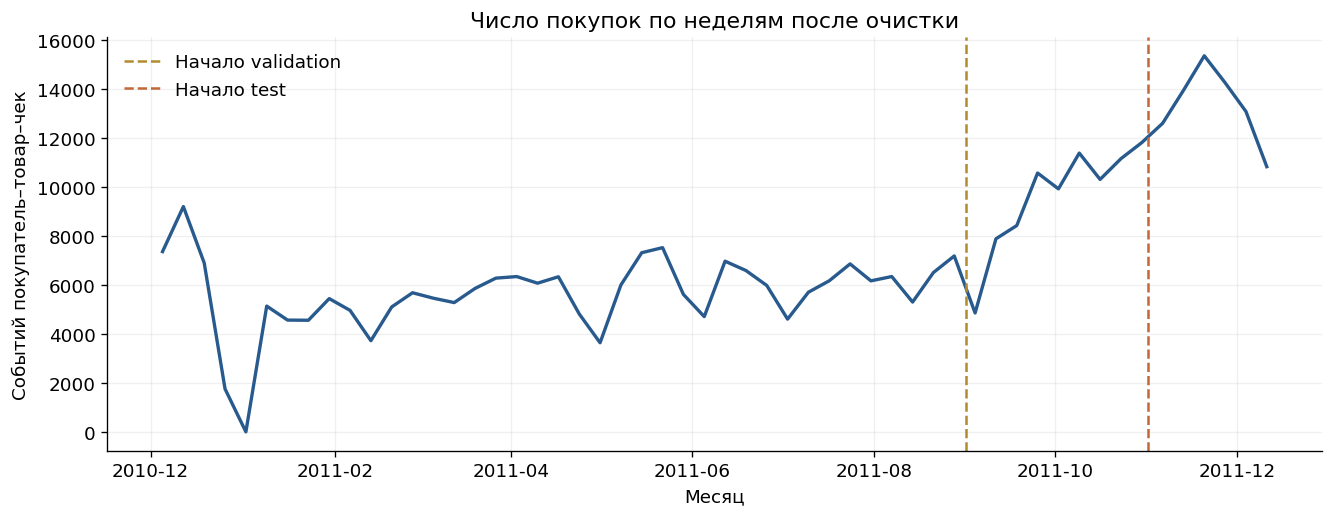

Последняя неделя неполная; длины validation и test различаются.


In [5]:
weekly = events.set_index('InvoiceDate').resample('W').size()
fig, ax = plt.subplots(figsize=(11, 4.2), layout='constrained')
ax.plot(weekly.index, weekly.values, color=BLUE, linewidth=2)
for date, label, color in [(VALID_START, 'Начало validation', GOLD), (TEST_START, 'Начало test', ORANGE)]:
    ax.axvline(date, color=color, linestyle='--', label=label)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.set(title='Число покупок по неделям после очистки', xlabel='Месяц', ylabel='Событий покупатель–товар–чек')
ax.legend(frameon=False)
fig.savefig(RESULTS/'eda_time.png', bbox_inches='tight')
plt.show()
print('Последняя неделя неполная; длины validation и test различаются.')

## 3. Протокол оценки и признаки
**Глобальное временное разбиение**, фиксированное до поиска настроек:

- Train: дата < 01.09.2011.
- Validation: 01.09.2011 ≤ дата < 01.11.2011.
- Test: 01.11.2011 ≤ дата ≤ конец набора.

В validation все модели обучаются на train. После выбора всех настроек каждая модель обучается заново на train + validation; test не участвует ни в выборе гиперпараметров, ни в признаках, ни в early stopping. Чеки не пересекают временные границы. Время трактуется как локальная дата источника без придуманной временной зоны.

**Кандидаты:** весь каталог товаров, наблюдавшихся до соответствующей границы, минус все ранее купленные товары пользователя. Отрицательная подвыборка при оценке не используется. Каталог фиксирован на начало окна, внутри окна история не обновляется. Новые покупатели и новые товары не оцениваются; также исключены пользователи без хотя бы одного нового релевантного товара. Это условная warm-start оценка, не качество на всех посетителях магазина. Число исключений выводится отдельно; cold-user и cold-item группы могут пересекаться.

**Релевантность для всех моделей:** бинарный факт положительной покупки нового товара в будущем окне, независимо от количества и обучающего таргета. Одна пара user-item входит в ground truth один раз. Метрики усредняются по пользователям, каждому придаётся одинаковый вес.

Для FM: one-hot user ID, item ID, multi-hot слова названия (латинские слова длиной ≥3, document frequency ≥3), one-hot исторический ценовой диапазон (границы 1, 2, 3, 5, 10, 20 GBP). Слова описывают тип/материал/цвет, цена — ценовой сегмент. Словарь, последнее известное название и медианная цена строятся **только по обучающему окну**. Новые слова не получают признака. На test словарь перестраивается по train+validation, одинаково до доступа к test-метрикам. FM без метаданных — контролируемая абляция с теми же настройками оптимизации.

In [6]:
train_events = events[events.InvoiceDate < VALID_START].copy()
valid_events = events[(events.InvoiceDate >= VALID_START) & (events.InvoiceDate < TEST_START)].copy()
test_events = events[events.InvoiceDate >= TEST_START].copy()
assert train_events.InvoiceDate.max() < valid_events.InvoiceDate.min()
assert valid_events.InvoiceDate.max() < test_events.InvoiceDate.min()
assert not set(train_events.InvoiceNo) & set(valid_events.InvoiceNo)
assert not set(valid_events.InvoiceNo) & set(test_events.InvoiceNo)
train = build_training(train_events, VALID_START)
valid_truth, valid_audit = evaluation_cohort(valid_events, train)
split_sizes = pd.DataFrame([{'split': name, 'events': len(frame), 'users': frame.CustomerID.nunique(),
                             'items': frame.StockCode.nunique()} for name, frame in
                           [('train', train_events), ('validation', valid_events), ('test', test_events)]]).set_index('split')
display(split_sizes)
display(pd.Series(valid_audit, name='Validation').to_frame())
print('Train: слов в словаре FM:', len(train.vocabulary), '; ширина item-признаков:', train.features.shape[1])

,events,users,items
split,,,
train,221075,3314,3388
validation,86984,2133,2859
test,78267,1904,2766


,Validation
future_unique_pairs,76981
cold_user_pairs,20453
cold_item_pairs,6266
warm_pairs,51744
already_seen_pairs,18527
novel_relevant_pairs,33217
evaluated_users,1407
future_users,2133
catalog_items,3388


Train: слов в словаре FM: 858 ; ширина item-признаков: 9


,Значение
товаров в train,3388.00
пустых названий,0.00
уникальных названий,3361.00
слов в словаре,858.00
медианная цена GBP,1.95
стран в train,36.00


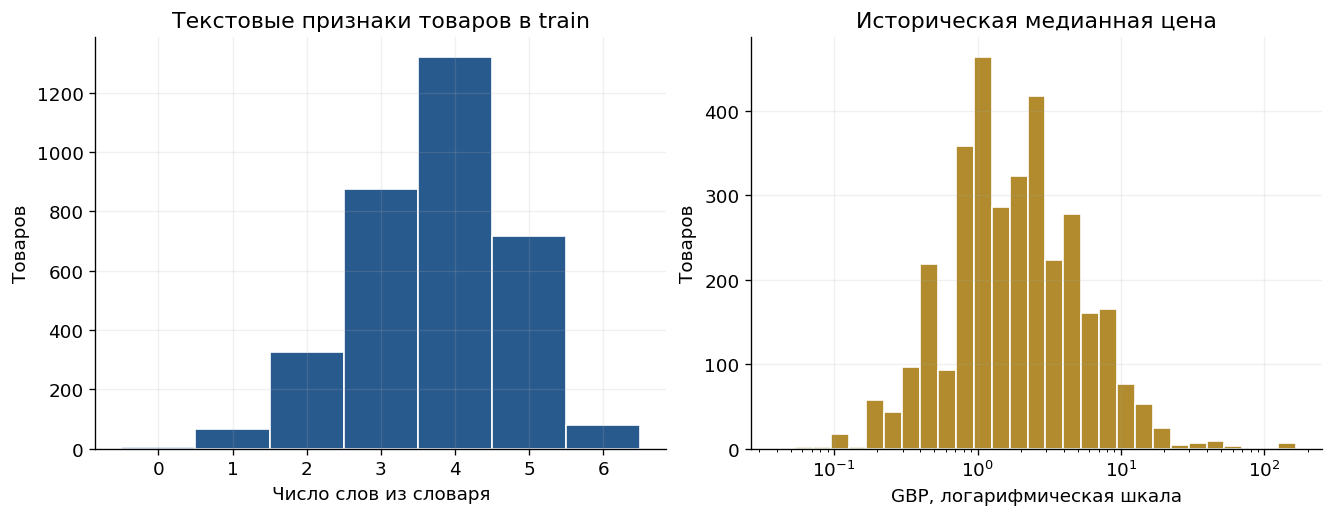

In [7]:
meta = train.metadata
feature_summary = pd.Series({'товаров в train': len(meta), 'пустых названий': int((meta.Description.str.len()==0).sum()),
    'уникальных названий': meta.Description.nunique(), 'слов в словаре': len(train.vocabulary),
    'медианная цена GBP': meta.UnitPrice.median(), 'стран в train': train_events.Country.nunique()})
display(feature_summary.to_frame('Значение'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
lengths = (train.features[:,1:-1] != 0).sum(axis=1)
axes[0].hist(lengths, bins=np.arange(lengths.max()+2)-.5, color=BLUE, edgecolor='white')
axes[0].set(title='Текстовые признаки товаров в train', xlabel='Число слов из словаря', ylabel='Товаров')
axes[1].hist(meta.UnitPrice, bins=np.geomspace(meta.UnitPrice.min(), meta.UnitPrice.max()+1, 30), color=GOLD, edgecolor='white')
axes[1].set(xscale='log', title='Историческая медианная цена', xlabel='GBP, логарифмическая шкала', ylabel='Товаров')
fig.savefig(RESULTS/'eda_metadata.png', bbox_inches='tight')
plt.show()

### Метрики при K = 10
Пусть $R_u$ — множество новых релевантных товаров, $L_u$ — рекомендованный список.

$$\operatorname{Recall@10}(u)=\frac{|R_u\cap L_u[:10]|}{|R_u|}.$$

Recall показывает, какая доля будущих новых покупок попала в десять рекомендаций. У покупателей с большим будущим набором верхняя граница Recall@10 может быть ниже 1.

$$\operatorname{NDCG@10}(u)=\frac{\sum_{r=1}^{10}\mathbf1[L_{ur}\in R_u]/\log_2(r+1)}{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}.$$

NDCG — **основная метрика, выбранная до подбора**: учитывает релевантность и положение в ограниченной витрине. Дополнительно Coverage@10 — доля каталога, попавшая хотя бы в один список: диагностирует концентрацию рекомендаций, не заменяет точность. Равные scores разрешаются по возрастанию внутреннего item ID, построенного сортировкой StockCode. Все модели используют одну реализацию top-K и метрик.

## 4. Модели и формулы
Пусть $X_{ui}=\mathbf1[n_{ui}>0]$, $n_{ui}$ — число разных чеков с товаром $i$ у пользователя $u$ до границы обучения.

### 4.1. ItemKNN — `models/item_knn.py`
Косинусное сходство со shrinkage:
$$s_{ij}=\frac{X_{:i}^{T}X_{:j}}{\|X_{:i}\|\|X_{:j}\|}\frac{m_{ij}}{m_{ij}+\beta},\quad m_{ij}=X_{:i}^{T}X_{:j},\quad s_{ii}=0.$$
Для каждого целевого товара оставляем $k$ ближайших соседей: $\hat r_{ui}=\sum_{j\in N_k(i)}X_{uj}s_{ji}$. При $\beta=0$ это обычный cosine для пар с пересечением; пары без пересечения имеют сходство 0. Матрица после отбора соседей может быть несимметричной.

### 4.2. iALS — `models/ials.py`
$$p_{ui}=\mathbf1[n_{ui}>0],\quad c_{ui}=1+\alpha\log(1+n_{ui}),$$
$$\min_{U,V}\sum_{u,i}c_{ui}(p_{ui}-U_u^TV_i)^2+\lambda(\|U\|_F^2+\|V\|_F^2).$$
Ненаблюдавшиеся пары имеют $p=0,c=1$ и входят в цель. При фиксированном $V$:
$$U_u=(V^TV+V_{I_u}^T(C_u-I)V_{I_u}+\lambda I)^{-1}V_{I_u}^TC_up_u.$$
Аналогично обновляются товары. В коде решается линейная система, явная обратная матрица не вычисляется. Используются 12 полных чередований; отрицательные примеры для ALS не сэмплируются.

### 4.3. EASE — `models/ease.py`
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}(B)=0.$$
Для $P=(X^TX+\lambda I)^{-1}$ получаем $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, $B_{jj}=0$. Предсказания $XB$. Используется разложение Холецкого; отрицательные коэффициенты сохраняются. Плотная item-item матрица приемлема для этого каталога, но память растёт как $O(|I|^2)$.

### 4.4. FM — `models/fm.py`
Для sparse feature vector $z$:
$$f(z)=w_0+\sum_jw_jz_j+\frac12\sum_{f=1}^d\left[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2\right].$$
Обучаем логистическую binary cross-entropy через собственную реализацию формулы и разрешённый PyTorch autograd/Adam. За эпоху используем каждую уникальную положительную train-пару и три равномерных отрицательных товара, которых нет в истории пользователя на границе обучения. Повторы отрицательных примеров допускаются; в следующей эпохе выборка обновляется. Validation/test при отборе отрицательных не просматриваются. Поэтому некоторые отрицательные примеры могут стать покупками в будущем — естественная неопределённость implicit feedback. `weight_decay=1e-5` в Adam задаёт L2-регуляризацию; bias тоже регуляризуется.

FM включает взаимодействия всех активных признаков, в том числе между метапризнаками товара. Для быстрого полного ранжирования используется точное разложение на скалярный user bias, item bias и произведение user-вектора на сумму item feature-векторов. Его равенство исходной формуле проверяется тестом. Вероятности при negative sampling не калиброваны; для ранжирования используются logits.

### 4.5. Собственный частотно-временной таргет — `models/custom_ials.py`
Для $a_{ui}$ — дней с последней покупки до границы обучения:
$$p^*_{ui}=\begin{cases}(1-\exp(-n_{ui}/2))\exp(-a_{ui}/\tau),&n_{ui}>0,\\0,&n_{ui}=0.\end{cases}$$
Это **изменение целевого значения**, а не только confidence: единичная покупка даёт меньший сигнал, повторения насыщаются, старые интересы ослабевают. Цель остаётся weighted least squares с тем же $c_{ui}=1+\alpha\log(1+n_{ui})$, что у базового iALS. Таргет — эвристика интенсивности предпочтения, а не оценка вероятности покупки.

Для контролируемого сравнения rank, alpha, lambda, seed и число итераций берём из выбранного базового iALS и меняем только preference target. Для $\tau$ проверяем 90, 180, 365 дней. Релевантность на test при этом остаётся бинарной. Гипотеза: недавние повторяемые интересы полезны для новых товаров; обратная возможность — потеря полезных старых интересов и чрезмерное уменьшение целевого масштаба. Последнее также меняет эффективную силу регуляризации: наблюдаемый эффект относится ко всему выбранному преобразованию таргета.

**Численная реализация:** плотные произведения выполняются через BLAS из SciPy с явной проверкой конечности операндов и результата. Это устраняет предупреждения NumPy/Accelerate на macOS; формулы и настройки остаются прежними. Равенство проверяется отдельно через прямое суммирование `einsum(optimize=False)`.


## 5. Подбор на validation
Пространство поиска задано в `experiment.py` до вычисления метрик. Для каждой модели выбирается максимум NDCG@10; при равенстве — первая конфигурация в фиксированном порядке. Размерности факторов и число итераций ALS зафиксированы ради умеренного бюджета. Это ограниченный, не исчерпывающий поиск. Для Custom iALS после выбора базового iALS подбирается только временная константа. Test в этой секции не оценивается.

In [8]:
search_table = pd.DataFrame([{'Модель': name, 'Конфигураций': len(configs), 'Пространство': str(configs)} for name, configs in SEARCH.items()])
for name, configs in SEARCH.items():
    display(Markdown('**'+name+'**'))
    display(pd.DataFrame(configs))
display(Markdown('**Custom iALS:** выбранные параметры iALS + tau_days ∈ {90, 180, 365}; saturation = 2. **FM IDs only:** выбранные параметры FM, metadata=False.'))

**ItemKNN**

,k,shrink
0,30,0
1,30,20
2,100,0
3,100,20


**iALS**

,factors,reg,alpha,iterations,seed
0,32,1.0,5.0,12,42
1,32,1.0,20.0,12,42
2,32,10.0,5.0,12,42
3,32,10.0,20.0,12,42


**EASE**

,reg
0,10.0
1,100.0
2,500.0


**FM**

,factors,lr,weight_decay,epochs,negatives,batch_size,metadata,seed
0,32,0.005,0.00001,4,3,4096,True,42
1,32,0.005,0.00001,8,3,4096,True,42


**Custom iALS:** выбранные параметры iALS + tau_days ∈ {90, 180, 365}; saturation = 2. **FM IDs only:** выбранные параметры FM, metadata=False.

In [9]:
experiment_start = time.perf_counter()
validation, selected = search_models(train, valid_truth, RESULTS)
display(validation[['model','NDCG@10','Recall@10','Coverage@10','fit_seconds']].round(5))

ItemKNN: NDCG@10=0.10228, Recall@10=0.05485


ItemKNN: NDCG@10=0.10862, Recall@10=0.05731


ItemKNN: NDCG@10=0.10604, Recall@10=0.05420


ItemKNN: NDCG@10=0.10853, Recall@10=0.05472


iALS: NDCG@10=0.09528, Recall@10=0.05520


...

FM: NDCG@10=0.07956, Recall@10=0.04106


Custom iALS: NDCG@10=0.09092, Recall@10=0.04851


Custom iALS: NDCG@10=0.09542, Recall@10=0.05136


Custom iALS: NDCG@10=0.09751, Recall@10=0.05346


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds
0,ItemKNN,0.10228,0.05485,0.39876,0.60306
1,ItemKNN,0.10862,0.05731,0.29634,0.52276
2,ItemKNN,0.10604,0.05420,0.36393,0.51582
3,ItemKNN,0.10853,0.05472,0.26417,0.53778
4,iALS,0.09528,0.05520,0.23613,2.55751
5,iALS,0.08110,0.04854,0.31995,2.44807
6,iALS,0.09704,0.05530,0.22934,2.49777
7,iALS,0.08251,0.05016,0.31198,2.42205
8,EASE,0.09316,0.05229,0.38695,0.52528
9,EASE,0.10932,0.06051,0.32143,0.47067


In [10]:
chosen_table = pd.DataFrame([{'model': name, **params} for name, params in selected.items()]).set_index('model')
display(chosen_table.T.fillna('—'))
assert (RESULTS/'selected_params.json').exists()
print('Настройки зафиксированы. Следующая секция использует test только для финальной оценки.')

model,ItemKNN,iALS,EASE,FM,Custom iALS,FM IDs only
k,30.0,—,—,—,—,—
shrink,20.0,—,—,—,—,—
factors,—,32.0,—,32.0,32.0,32.0
reg,—,10.0,500.0,—,10.0,—
alpha,—,5.0,—,—,5.0,—
iterations,—,12.0,—,—,12.0,—
seed,—,42.0,—,42.0,42.0,42.0
lr,—,—,—,0.005,—,0.005
weight_decay,—,—,—,0.00001,—,0.00001
epochs,—,—,—,8.0,—,8.0


Настройки зафиксированы. Следующая секция использует test только для финальной оценки.


## 6. Финальное сравнение на test
Все выбранные модели обучаются заново на train + validation. Общий каталог, история исключения и множество оцениваемых пользователей строятся один раз для всех моделей. Таблица `test_results.csv` содержит метрики и выбранные параметры. Время измерено на текущем CPU в одном потоке; это ориентир, не аппаратно-независимый benchmark.

In [11]:
final_train_events = events[events.InvoiceDate < TEST_START].copy()
final_train = build_training(final_train_events, TEST_START)
test_truth, test_audit = evaluation_cohort(test_events, final_train)
display(pd.DataFrame([valid_audit, test_audit], index=['validation','test']).T)
(RESULTS/'cohort_audit.json').write_text(json.dumps({'validation': valid_audit, 'test': test_audit}, indent=2, default=int))
results, per_user, examples = final_evaluation(final_train, test_truth, selected, RESULTS)
print(f'Поиск и финальное обучение заняли {(time.perf_counter()-experiment_start)/60:.1f} мин.')
display(results[['model','NDCG@10','Recall@10','Coverage@10','fit_seconds','eval_seconds']].round(5))

,validation,test
future_unique_pairs,76981,67524
cold_user_pairs,20453,11888
cold_item_pairs,6266,733
warm_pairs,51744,54983
already_seen_pairs,18527,22183
novel_relevant_pairs,33217,32800
evaluated_users,1407,1440
future_users,2133,1904
catalog_items,3388,3607


Test ItemKNN: NDCG@10=0.08998, Recall@10=0.05391


Test iALS: NDCG@10=0.09219, Recall@10=0.05580


Test EASE: NDCG@10=0.10285, Recall@10=0.06324


Test FM: NDCG@10=0.07256, Recall@10=0.04199


Test Custom iALS: NDCG@10=0.08572, Recall@10=0.05330


Test FM IDs only: NDCG@10=0.07136, Recall@10=0.03986


Поиск и финальное обучение заняли 2.0 мин.


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,eval_seconds
0,EASE,0.10285,0.06324,0.27862,0.67349,1.60671
1,iALS,0.09219,0.05580,0.23593,2.84778,0.24613
2,ItemKNN,0.08998,0.05391,0.31106,0.68980,0.22005
3,Custom iALS,0.08572,0.05330,0.18159,3.07015,0.24939
4,FM,0.07256,0.04199,0.21403,8.33981,0.27448
5,FM IDs only,0.07136,0.03986,0.14583,2.82522,0.25281


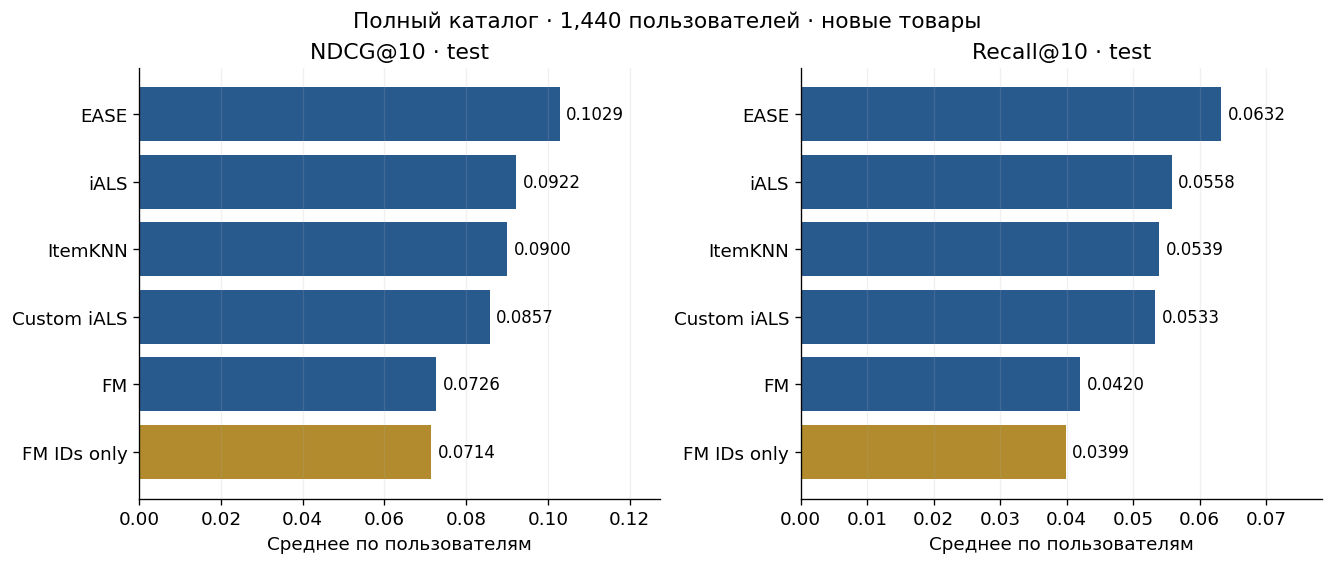

In [12]:
ordered = results.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
for ax, metric in zip(axes, ['NDCG@10','Recall@10']):
    bars = ax.barh(ordered.model, ordered[metric], color=[GOLD if x=='FM IDs only' else BLUE for x in ordered.model])
    ax.bar_label(bars, fmt='%.4f', padding=4, fontsize=10)
    ax.set_xlim(0, ordered[metric].max()*1.24)
    ax.set(title=metric+' · test', xlabel='Среднее по пользователям')
    ax.grid(axis='x', alpha=.18)
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Полный каталог · {len(test_truth):,} пользователей · новые товары', fontsize=13)
fig.savefig(RESULTS/'model_comparison.png', bbox_inches='tight')
plt.show()

### Абляции и неопределённость
Парный bootstrap по пользователям: 2 000 выборок с возвращением, seed=42; 95% percentile-интервал для разности NDCG@10. Для каждого сравнения у моделей совпадают пользователи. Интервал описывает вариацию состава пользователей этого test-окна; он не учитывает другие временные периоды, случайные зерна обучения и зависимость покупателей через общие товары. Это не доказательство причинного эффекта или универсального превосходства.

In [13]:
contrasts = []
for a, b, label in [('Custom iALS','iALS','Custom iALS − iALS'), ('FM','FM IDs only','FM с метаданными − FM IDs only')]:
    contrasts.append({'comparison': label, **paired_bootstrap(per_user[a]['NDCG@10'], per_user[b]['NDCG@10'])})
contrasts = pd.DataFrame(contrasts)
display(contrasts.round(6))
contrasts.to_csv(RESULTS/'paired_bootstrap.csv', index=False)

,comparison,mean_delta,ci_low,ci_high
0,Custom iALS − iALS,-0.006461,-0.011532,-0.001439
1,FM с метаданными − FM IDs only,0.001202,-0.004448,0.007220


### Пример персональной рекомендации
Показываем top-10 победителя среди пяти основных моделей для первого по внутреннему ID пользователя test-когорты. Это фиксированное правило выбора примера, не поиск удачного пользователя. В таблице рядом — названия, известные до test, и факт будущей покупки. В открытом репозитории исходный CustomerID не раскрывается.

In [14]:
main_results = results[results.model != 'FM IDs only']
winner = main_results.iloc[0]['model']
example_user = sorted(test_truth)[0]
example_items = examples[winner][0]
example = pd.DataFrame({'rank': np.arange(1,11),
                        'товар': final_train.items[example_items],
                        'известное название': final_train.metadata.iloc[example_items].Description.to_numpy(),
                        'покупка на test': np.isin(example_items, test_truth[example_user])})
assert not set(example_items) & set(final_train.binary[example_user].indices)
display(example)

,rank,товар,известное название,покупка на test
0,1,21977,PACK OF 60 PINK PAISLEY CAKE CASES,False
1,2,22730,ALARM CLOCK BAKELIKE IVORY,False
2,3,23245,SET OF 3 REGENCY CAKE TINS,False
3,4,21212,PACK OF 72 RETROSPOT CAKE CASES,False
4,5,84997A,CHILDRENS CUTLERY POLKADOT GREEN,False
5,6,22951,60 CAKE CASES DOLLY GIRL DESIGN,False
6,7,21790,VINTAGE SNAP CARDS,False
7,8,84378,SET OF 3 HEART COOKIE CUTTERS,False
8,9,21213,PACK OF 72 SKULL CAKE CASES,False
9,10,23148,MINIATURE ANTIQUE ROSE HOOK IVORY,False


## 7. Выводы
Ниже текст формируется из полученных результатов, чтобы при повторном запуске числа и выводы оставались согласованными.

In [15]:
best = main_results.iloc[0]
runner = main_results.iloc[1]
custom_delta = contrasts.iloc[0]
fm_delta = contrasts.iloc[1]
def describe_effect(row):
    if row.ci_low > 0:
        return 'положительная разность; интервал не пересекает ноль'
    if row.ci_high < 0:
        return 'отрицательная разность; интервал не пересекает ноль'
    return 'интервал пересекает ноль; уверенного различия на этой когорте не видно'
text = f"""
1. **Лучшая из пяти основных моделей — {best['model']}**: NDCG@10 = **{best['NDCG@10']:.5f}**, Recall@10 = **{best['Recall@10']:.5f}**. Следом {runner['model']} с NDCG@10 = {runner['NDCG@10']:.5f}. Выбранные настройки приведены выше; этот порядок относится к текущему временному окну и заданному бюджету поиска.
2. **Собственный таргет:** разность Custom iALS − iALS равна **{custom_delta.mean_delta:+.5f}** NDCG@10, 95% CI [{custom_delta.ci_low:+.5f}; {custom_delta.ci_high:+.5f}]: {describe_effect(custom_delta)}. Confidence и остальные параметры ALS совпадают, поэтому сравнивается выбранное преобразование целевого сигнала. Оно не обязано улучшать результат.
3. **Метаданные FM:** разность FM − FM IDs only равна **{fm_delta.mean_delta:+.5f}**, 95% CI [{fm_delta.ci_low:+.5f}; {fm_delta.ci_high:+.5f}]: {describe_effect(fm_delta)}. Абляция фиксирует оптимизатор и эпохи; отдельный подбор лучшего ID-only варианта не проводился, поэтому это эффект добавления признаков при фиксированном режиме обучения.
4. Test оценивает **{test_audit['evaluated_users']:,}** из {test_audit['future_users']:,} покупателей будущего окна, по **{test_audit['novel_relevant_pairs']:,}** новым релевантным парам. Результат не распространяется напрямую на cold start, повторные покупки или пользователей без новых покупок. Популярность, сезонность подарков и оптовые заказы могут влиять на сравнение; offline-метрики не доказывают рост продаж.
"""
display(Markdown(text))
(RESULTS/'conclusions.txt').write_text(text, encoding='utf-8');


1. **Лучшая из пяти основных моделей — EASE**: NDCG@10 = **0.10285**, Recall@10 = **0.06324**. Следом iALS с NDCG@10 = 0.09219. Выбранные настройки приведены выше; этот порядок относится к текущему временному окну и заданному бюджету поиска.
2. **Собственный таргет:** разность Custom iALS − iALS равна **-0.00646** NDCG@10, 95% CI [-0.01153; -0.00144]: отрицательная разность; интервал не пересекает ноль. Confidence и остальные параметры ALS совпадают, поэтому сравнивается выбранное преобразование целевого сигнала. Оно не обязано улучшать результат.
3. **Метаданные FM:** разность FM − FM IDs only равна **+0.00120**, 95% CI [-0.00445; +0.00722]: интервал пересекает ноль; уверенного различия на этой когорте не видно. Абляция фиксирует оптимизатор и эпохи; отдельный подбор лучшего ID-only варианта не проводился, поэтому это эффект добавления признаков при фиксированном режиме обучения.
4. Test оценивает **1,440** из 1,904 покупателей будущего окна, по **32,800** новым релевантным парам. Результат не распространяется напрямую на cold start, повторные покупки или пользователей без новых покупок. Популярность, сезонность подарков и оптовые заказы могут влиять на сравнение; offline-метрики не доказывают рост продаж.


### Ограничения и продолжение

- Один временной split, один seed и компактный поиск. Для устойчивого вывода нужны несколько rolling-origin окон и несколько seed при неизменном протоколе; test текущего эксперимента для дальнейшего подбора использовать нельзя.
- Модель видит покупки, а не показы: отсутствие покупки не означает неприязнь. Нет учёта наличия товара на складе, показов и маркетинговых кампаний. Каталог — все когда-либо наблюдавшиеся до границы товары.
- Исторические цены и названия — доступные на момент рекомендации прокси метаданных, не отдельный каталог с историей изменений. Служебные коды отфильтрованы эвристикой. Возвраты не используются как отрицательные оценки.
- Длинная история оптовиков влияет на обучение; макроусреднение только при оценке не устраняет это смещение. Разные длины validation/test не позволяют напрямую трактовать изменение метрик между ними как улучшение модели.
- Добавление метаданных проверено для одной схемы токенизации и фиксированных ценовых диапазонов. Вывод не переносится на любые текстовые признаки.

### Источники методов

- Hu, Koren, Volinsky (2008), [Collaborative Filtering for Implicit Feedback Datasets](https://yifanhu.net/PUB/cf.pdf).
- Steck (2019), [Embarrassingly Shallow Autoencoders for Sparse Data](https://arxiv.org/abs/1905.03375).
- Rendle (2010), [Factorization Machines, DOI: 10.1109/ICDM.2010.127](https://doi.org/10.1109/ICDM.2010.127), [страница автора с публикациями](https://libfm.org/).

Использованы описания методов, но не готовые реализации рекомендательных алгоритмов. Код обучения, scoring, top-K и метрик находится в этом репозитории. NumPy/SciPy решают линейную алгебру; PyTorch предоставляет autograd и оптимизатор.